# Description

Exercise 1 on equities, as asked on #733: the same PnL vs hit rate
experiment as `exercise1.ipynb`, on SPY, next to BTC.

- SPY from Yahoo Finance, adjusted for dividends and splits
- Yahoo only has hourly bars for the last 730 days, so the hourly
  comparison uses 2024-11-01 to 2026-10-01 for both SPY and BTC
- Daily bars use 2020-01-01 to 2026-10-01 as in Exercise 1, plus the full
  SPY history from 1993

Differences between the two markets that matter here:
- SPY trades 6.5 hours a day, 5 days a week. BTC trades all the time
- So in the same period SPY has far fewer hourly and daily bars
- The first hourly bar of each SPY day includes the overnight move

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import tradability_utils as tu

## Config

In [2]:
# Each experiment: (name, symbol, interval, start, end, source).
EXPERIMENTS = [
    ("SPY 1h", "SPY", "1h", "2024-11-01", "2026-10-01", "yahoo"),
    ("BTC 1h", "BTCUSDT", "1h", "2024-11-01", "2026-10-01", "binance"),
    ("SPY 1d", "SPY", "1d", "2020-01-01", "2026-10-01", "yahoo"),
    ("BTC 1d", "BTCUSDT", "1d", "2020-01-01", "2026-10-01", "binance"),
    ("SPY 1d since 1993", "SPY", "1d", "1993-01-01", "2026-10-01", "yahoo"),
]
HIT_RATES = [
    0.48,
    0.49,
    0.50,
    0.505,
    0.51,
    0.515,
    0.52,
    0.525,
    0.53,
    0.54,
    0.55,
    0.56,
    0.58,
    0.60,
]
N_SIMS = 1000
MODES = ["shuffle", "bernoulli"]

## Load the data

In [3]:
rets = {}
for name, symbol, interval, start, end, source in EXPERIMENTS:
    prices = tu.load_prices(symbol, interval, start, end, source=source)
    rets[name] = tu.compute_returns(prices)
# Number of trades, trades per year, and N_eff for each experiment.
rows = []
for name, symbol, interval, start, end, source in EXPERIMENTS:
    r = rets[name]
    n = len(r)
    n_years = (pd.Timestamp(end) - pd.Timestamp(start)).days / 365.25
    n_eff = tu.compute_effective_n(r)
    rows.append(
        {
            "name": name,
            "start": start,
            "end": end,
            "n": n,
            "n_per_year": round(n / n_years),
            "n_eff": round(n_eff),
            "n_eff / n": round(n_eff / n, 2),
            "p_star_spec": round(tu.compute_min_hit_rate(n), 4),
            "p_star_eff": round(tu.compute_min_hit_rate(n_eff), 4),
        }
    )
n_stats = pd.DataFrame(rows).set_index("name")
n_stats

,start,end,n,n_per_year,n_eff,n_eff / n,p_star_spec,p_star_eff
name,,,,,,,,
SPY 1h,2024-11-01,2026-10-01,3315,1732,1114,0.34,0.5143,0.5246
BTC 1h,2024-11-01,2026-10-01,16775,8765,7089,0.42,0.5064,0.5098
SPY 1d,2020-01-01,2026-10-01,1694,251,734,0.43,0.5200,0.5304
BTC 1d,2020-01-01,2026-10-01,2464,365,1094,0.44,0.5166,0.5249
SPY 1d since 1993,1993-01-01,2026-10-01,8474,251,3761,0.44,0.5089,0.5134


## Simulate the PnL

In [4]:
results = []
for name, symbol, interval, start, end, source in EXPERIMENTS:
    for mode in MODES:
        df = tu.run_experiment(
            symbol,
            interval,
            start,
            end,
            HIT_RATES,
            N_SIMS,
            mode=mode,
            source=source,
        )
        df["name"] = name
        results.append(df)
results = pd.concat(results, ignore_index=True)
# Compute P(PnL > 0) for each experiment, mode, and hit rate.
prob = (
    results.assign(win=results["pnl"] > 0)
    .groupby(["name", "mode", "hit_rate"])["win"]
    .mean()
    .reset_index()
)
prob.pivot_table(index=["name", "mode"], columns="hit_rate", values="win")

hit_rate                     0.480  0.490  0.500  0.505  0.510  0.515  0.520  \
name              mode                                                         
BTC 1d            bernoulli  0.093  0.253  0.503  0.616  0.738  0.819  0.883   
                  shuffle    0.046  0.211  0.515  0.665  0.820  0.906  0.957   
BTC 1h            bernoulli  0.000  0.053  0.479  0.794  0.956  0.996  0.999   
                  shuffle    0.000  0.016  0.478  0.860  0.987  0.999  1.000   
SPY 1d            bernoulli  0.136  0.295  0.480  0.591  0.712  0.792  0.862   
                  shuffle    0.069  0.233  0.492  0.627  0.762  0.837  0.923   
SPY 1d since 1993 bernoulli  0.002  0.104  0.521  0.747  0.892  0.968  0.993   
                  shuffle    0.000  0.044  0.500  0.801  0.950  0.993  1.000   
SPY 1h            bernoulli  0.084  0.237  0.482  0.620  0.733  0.833  0.910   
                  shuffle    0.053  0.218  0.525  0.682  0.807  0.899  0.964   

hit_rate                     0.525  0.530  0.540  0.550  0.560  0.580  0.600  
name              mode                                                        
BTC 1d            bernoulli  0.938  0.976  0.995  0.999    1.0    1.0    1.0  
                  shuffle    0.985  0.995  0.998  1.000    1.0    1.0    1.0  
BTC 1h            bernoulli  1.000  1.000  1.000  1.000    1.0    1.0    1.0  
                  shuffle    1.000  1.000  1.000  1.000    1.0    1.0    1.0  
SPY 1d            bernoulli  0.917  0.954  0.988  0.999    1.0    1.0    1.0  
                  shuffle    0.957  0.981  0.997  1.000    1.0    1.0    1.0  
SPY 1d since 1993 bernoulli  1.000  1.000  1.000  1.000    1.0    1.0    1.0  
                  shuffle    1.000  1.000  1.000  1.000    1.0    1.0    1.0  
SPY 1h            bernoulli  0.950  0.979  0.995  0.999    1.0    1.0    1.0  
                  shuffle    0.981  0.995  0.999  1.000    1.0    1.0    1.0

## Probability of a positive PnL vs hit rate

Same lines as in `exercise1.ipynb`:
- gray dotted line: spec $p^* = \frac{1}{2} + \frac{z_q}{2 \sqrt{N}}$
- black dashed line: corrected $p^*$ with
  $N_{eff} = (\sum |r|)^2 / \sum r^2$
- red line: 95%

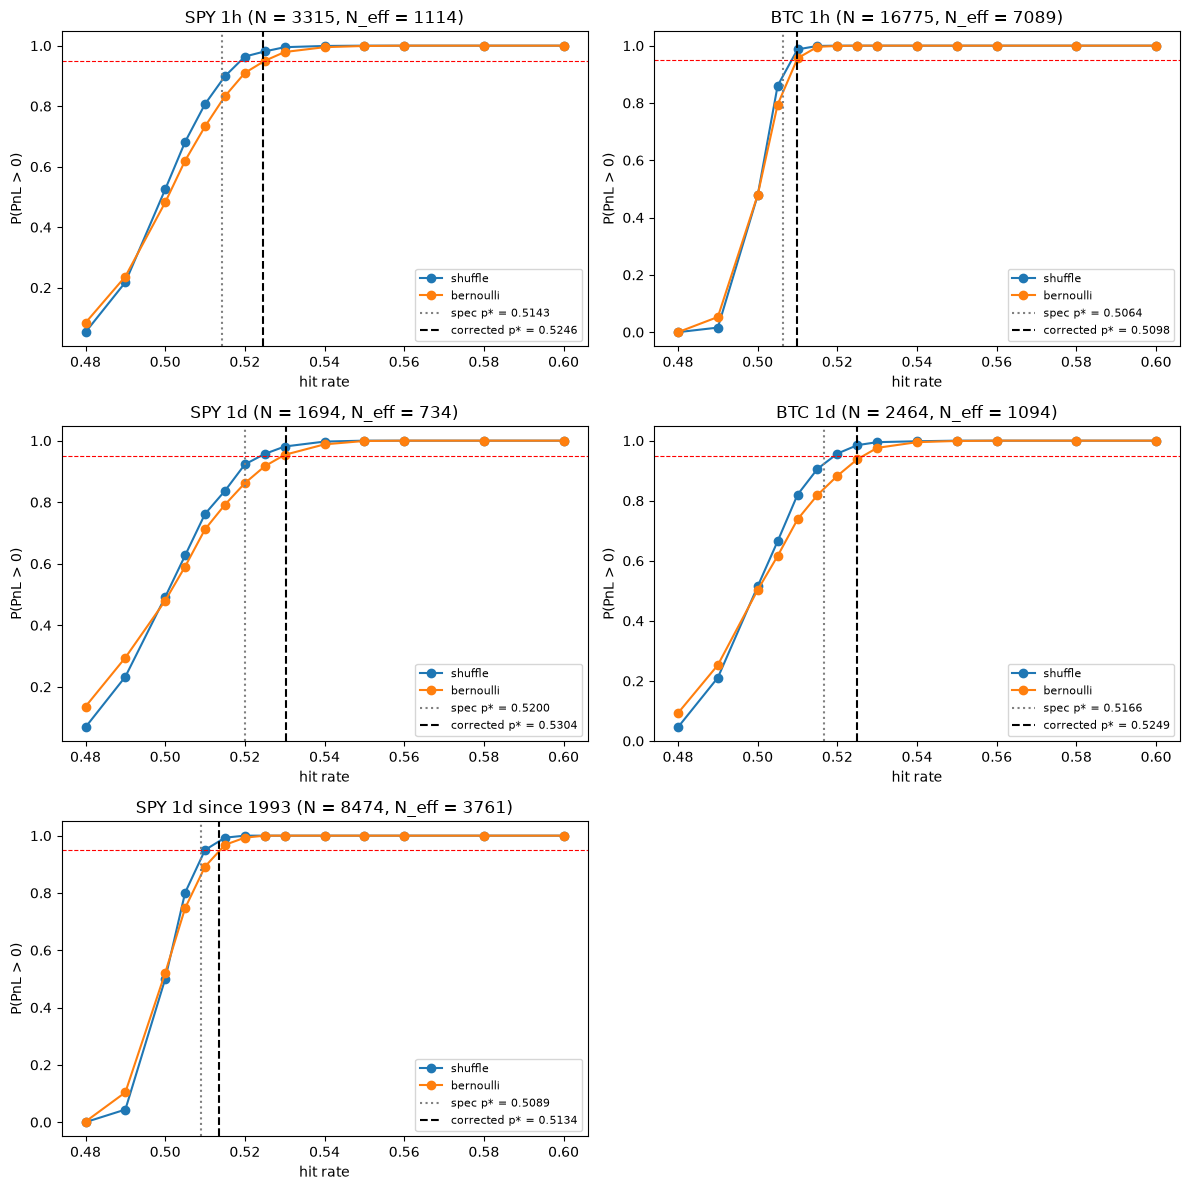

In [5]:
names = [experiment[0] for experiment in EXPERIMENTS]
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
for ax, name in zip(axes.flat, names):
    for mode in MODES:
        mask = (prob["name"] == name) & (prob["mode"] == mode)
        sub = prob[mask]
        ax.plot(sub["hit_rate"], sub["win"], marker="o", label=mode)
    stats = n_stats.loc[name]
    label = f"spec p* = {stats['p_star_spec']:.4f}"
    ax.axvline(stats["p_star_spec"], color="gray", linestyle=":", label=label)
    label = f"corrected p* = {stats['p_star_eff']:.4f}"
    ax.axvline(stats["p_star_eff"], color="black", linestyle="--", label=label)
    ax.axhline(0.95, color="red", linestyle="--", linewidth=0.8)
    n, n_eff = int(stats["n"]), int(stats["n_eff"])
    ax.set_title(f"{name} (N = {n}, N_eff = {n_eff})")
    ax.set_xlabel("hit rate")
    ax.set_ylabel("P(PnL > 0)")
    ax.legend(fontsize=8)
# Hide the unused subplot.
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

In [6]:
# Find the smallest simulated hit rate with P(PnL > 0) >= 95%.
crossing = (
    prob[prob["win"] >= 0.95]
    .groupby(["name", "mode"])["hit_rate"]
    .min()
    .unstack("mode")
)
crossing = crossing.join(n_stats[["n", "p_star_spec", "p_star_eff"]])
crossing.loc[names]

,bernoulli,shuffle,n,p_star_spec,p_star_eff
name,,,,,
SPY 1h,0.525,0.520,3315,0.5143,0.5246
BTC 1h,0.510,0.510,16775,0.5064,0.5098
SPY 1d,0.530,0.525,1694,0.5200,0.5304
BTC 1d,0.530,0.520,2464,0.5166,0.5249
SPY 1d since 1993,0.515,0.510,8474,0.5089,0.5134


## Overnight moves in hourly SPY

The first hourly bar of each day goes from the previous close to 10:30, so
it includes the overnight move. Check how much of the PnL it carries.

In [7]:
r = rets["SPY 1h"]
# The first bar of each New York trading day.
local_dates = r.index.tz_convert("America/New_York").date
is_first = ~pd.Series(local_dates, index=r.index).duplicated().to_numpy()
abs_r = np.abs(r.to_numpy())
overnight = pd.Series(
    {
        "share of bars": is_first.mean(),
        "share of sum |r|": abs_r[is_first].sum() / abs_r.sum(),
        "share of sum r^2": (abs_r[is_first] ** 2).sum() / (abs_r**2).sum(),
        "n_eff without first bars": tu.compute_effective_n(r[~is_first]),
    }
).round(3)
overnight

share of bars                  0.144
share of sum |r|               0.330
share of sum r^2               0.538
n_eff without first bars    1080.927
dtype: float64

## Observations

- The N_eff correction works for SPY too. In all five cases, the corrected
  p* lands where the bernoulli simulation crosses 95% (SPY 1h: 0.5246 vs
  0.525, SPY 1d: 0.5304 vs 0.530). The spec formula is too optimistic for
  SPY as well: at its value for SPY 1h (0.5143), the chance of profit is
  only about 85%
- SPY needs a higher hit rate than BTC at the same bar size, because it
  trades fewer hours. Over the same 2 years, SPY 1h has 3,315 bars and BTC
  1h has 16,775. To make money 95% of the time, SPY 1h needs about 52.5%,
  BTC 1h about 51%
- Hourly SPY over 2 years needs about the same hit rate as daily BTC over
  6.75 years (52.5-53%). What matters is the number of trades, not the bar
  size
- Daily SPY and daily BTC over 2020-2026 need almost the same hit rate
  (about 53%), even though BTC moves about 2.5x more per day. The scale of the
  moves does not matter for the chance of profit, only how many there are
  and how unequal they are
- Hourly SPY has the lowest N_eff / N (0.34) of all the cases. The first
  bar of each day includes the overnight move: it is 14% of the bars but
  carries 33% of the total |r| and 54% of the total r^2. Dropping these
  bars barely changes N_eff (1,114 to 1,081), so most of the hourly bars
  add little on their own
- With the full SPY history since 1993 (8,474 days), the 95% hit rate drops
  to about 51.5%
- Note: Yahoo only has hourly bars for the last 730 days. Once 2024-11-01
  is more than 730 days ago, the SPY 1h download will fail unless the
  cached file is kept